# Member 4 · XGBoost Weekly Illegal-Dumping Demand Forecasting

*DATA 245 | San José 311 | Intermediate experiment · Provisional*  
Train: 2020–2023 · Validate: 2024 · Final test: 2025 (held out)

## 1. Scope and contribution

The 311 data have no verified case-completion timestamp, so `date_last_updated` cannot reliably support the original closure-time regression. Under the agreed fallback, Member 4 predicts weekly illegal-dumping request counts by district using XGBoost.

Member 5 provides the shared district-week panel and forecasting benchmarks. Member 2 provides optional features. My contribution is the XGBoost feature comparison and error analysis by district and busy week.

Sections 4–6 focus on `member2_lags` when Member 2's features are available; otherwise they use `shared`. Section 3 compares both against other feature sets. The 2024 validation results are exploratory, not a claim about 2025 performance.

To reproduce: from the project root, run `python src/demand_forecasting.py` if the shared table is missing, then select **Run All**. No 2025 evaluation is performed.


## 2. Forecast protocol and leakage controls

- Target: next week's reported illegal-dumping requests per district, using complete Monday–Sunday weeks.
- Time split: 2018–2019 supplies historical lags; training uses 2020–2023, validation uses 2024, and 2025 remains untouched. Incomplete and split-crossing weeks are excluded from scoring.
- Information timing: lag and rolling features use only completed earlier weeks. During 2024, newly observed weeks can inform the next one-week-ahead forecast.
- Inputs: district encoding fitted on training data, historical demand, and calendar features. Optional inputs come from Member 2's existing feature code.
- XGBoost: squared-error regression with 250 trees, depth 4, learning rate 0.05, and seed 42; negative predictions are clipped to zero.
- Evaluation: MAE and RMSE (reports per district-week) on identical 2024 validation rows.

District boundaries, reporting coverage, and zero-count assumptions still require team confirmation; results are provisional.


In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image

# Find the repository whether Jupyter started from its root or a nested folder.
starts = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
roots = [p for p in starts
         if (p / 'src/demand_forecasting.py').is_file()
         and (p / 'notebooks/04_resolution_regression/member4_xgboost.py').is_file()]
if not roots:
    raise FileNotFoundError('Open a repository checkout containing Member 5 and Member 4 scripts.')
ROOT = roots[0]
# Load the EXACT script on disk, even when this notebook kernel previously imported
# an older version. This prevents the old-script/new-notebook KeyError.
import importlib.util
script_path = ROOT / 'notebooks/04_resolution_regression/member4_xgboost.py'
spec = importlib.util.spec_from_file_location('member4_xgboost_current', script_path)
if spec is None or spec.loader is None:
    raise ImportError(f'Cannot load current Member 4 script: {script_path}')
m4 = importlib.util.module_from_spec(spec)
spec.loader.exec_module(m4)
if getattr(m4, 'ARTIFACT_API_VERSION', None) != 2:
    raise RuntimeError('Member 4 Notebook and Python script are different versions. '
                       'Replace the full notebooks/04_resolution_regression folder, then Run All.')

with_member2 = (ROOT / 'src/eda_features.py').is_file()
outputs, manifest = m4.run(provisional=True, with_member2=with_member2)
if manifest.get('artifact_api_version') != m4.ARTIFACT_API_VERSION:
    raise RuntimeError('Member 4 run manifest does not match the notebook API version.')
primary_experiment = manifest['primary_analysis_experiment']
assert primary_experiment in outputs['validation_metrics']['experiment'].tolist()
print('Loaded Member 4 script:', script_path.relative_to(ROOT))
print('Member 2 feature module available:', with_member2)
print('Primary analysis experiment:', primary_experiment)
print('Member 5 validation-row cross-check:', manifest['team_validation_check'])


PROVISIONAL 2024 VALIDATION (per district-week)
  experiment  training_rows  validation_rows       mae      rmse
      shared           2080              520 14.170988 20.324934
member2_lags           2080              520 13.942414 20.195066
member2_full           2080              520 14.007051 20.355857
Primary district/busy-week/importance analysis: member2_lags
Team validation cross-check: passed
Files: results\member4_xgboost reports\figures\member4_xgboost
Loaded Member 4 script: notebooks\04_resolution_regression\member4_xgboost.py
Member 2 feature module available: True
Primary analysis experiment: member2_lags
Member 5 validation-row cross-check: {'team_validation_crosscheck': 'passed', 'team_poisson_rows': 520}


## 3. XGBoost feature comparison

The feature sets use identical XGBoost parameters, 2,080 training district-weeks, and 520 validation district-weeks. Only the input features change. `shared` remains the reference; Member 5's Poisson result is shown for context.

Differences on the 2024 validation set are exploratory and do not establish which configuration will perform best on the held-out 2025 test.


,experiment,analysis_role,training_rows,validation_rows,mae,rmse
0,shared,Comparator,2080,520,14.171,20.325
1,member2_lags,Primary focus,2080,520,13.942,20.195
2,member2_full,Comparator,2080,520,14.007,20.356


member2_lags minus shared: MAE -0.229; RMSE -0.130 reports/district-week.
Member 5 Poisson benchmark (2020–2023 training, for context):


,model,training_start,validation_rows,mae,rmse
5,poisson,2020,520,13.642699,19.131701


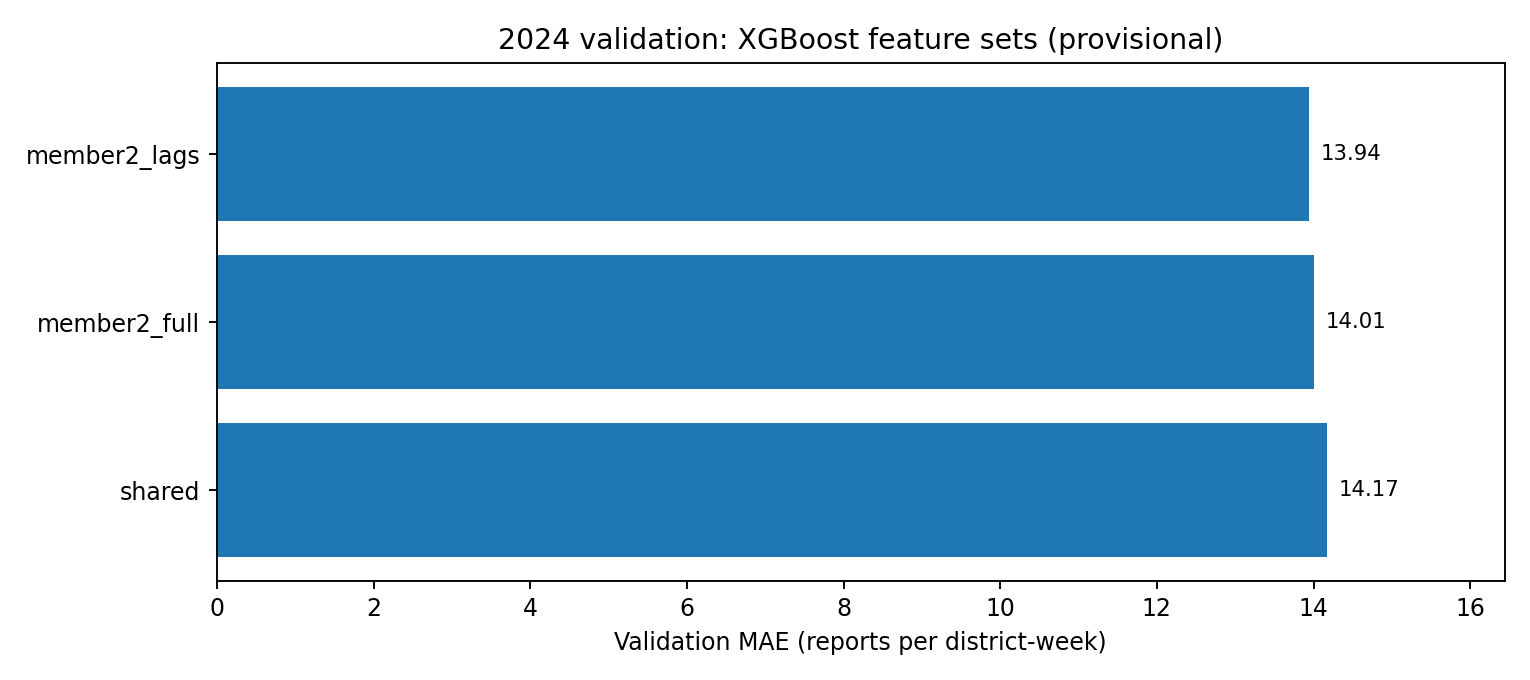

In [2]:
metrics = outputs['validation_metrics'][['experiment', 'training_rows', 'validation_rows', 'mae', 'rmse']].copy()
metrics['analysis_role'] = metrics.experiment.map(lambda x: 'Primary focus' if x == primary_experiment else 'Comparator')
display(metrics[['experiment', 'analysis_role', 'training_rows', 'validation_rows', 'mae', 'rmse']].round({'mae': 3, 'rmse': 3}))

shared_row = metrics.set_index('experiment').loc['shared']
focus_row = metrics.set_index('experiment').loc[primary_experiment]
if primary_experiment != 'shared':
    print(f"{primary_experiment} minus shared: MAE {focus_row.mae - shared_row.mae:+.3f}; "
          f"RMSE {focus_row.rmse - shared_row.rmse:+.3f} reports/district-week.")

team_file = ROOT / 'results/demand_forecasting/validation_metrics.csv'
if team_file.exists():
    team = pd.read_csv(team_file)
    benchmark_cols = {'model', 'training_start', 'validation_rows', 'mae', 'rmse'}
    if benchmark_cols.issubset(team.columns):
        poisson = team.loc[team['model'].eq('poisson') &
                           pd.to_numeric(team['training_start'], errors='coerce').eq(2020),
                           ['model', 'training_start', 'validation_rows', 'mae', 'rmse']]
        if not poisson.empty:
            print('Member 5 Poisson benchmark (2020–2023 training, for context):')
            display(poisson)
        else:
            print('No 2020-trained Poisson benchmark found in the shared results.')
    else:
        print('Member 5 metric schema changed; benchmark comparison omitted pending alignment.')
else:
    print('Member 5 validation metric table unavailable; team benchmark not shown.')
display(Image(filename=str(ROOT / 'reports/figures/member4_xgboost/model_comparison.png')))

## 4. District-level errors

For each district, we report MAE, RMSE, and mean bias (`prediction − actual`) across 52 validation weeks. Negative bias indicates underprediction.

These are errors in report counts, not population-adjusted measures or rankings of district service quality. The table and chart use the same primary XGBoost configuration as Sections 5–6.


District diagnostics for: member2_lags


,district,rows,mae,rmse,mean_bias_prediction_minus_actual
12,3,52,31.81,39.22,-13.60
14,5,52,19.46,26.26,-1.79
10,1,52,18.98,23.63,-4.97
11,2,52,14.64,19.59,-1.64
16,7,52,14.15,18.74,-2.48
15,6,52,10.92,14.32,-1.46
17,8,52,9.89,12.26,0.12
13,4,52,7.13,8.87,0.95
19,10,52,7.02,8.95,-0.44
18,9,52,5.43,6.57,0.85


Highest raw-count MAE: District 3 (31.81 reports/district-week).


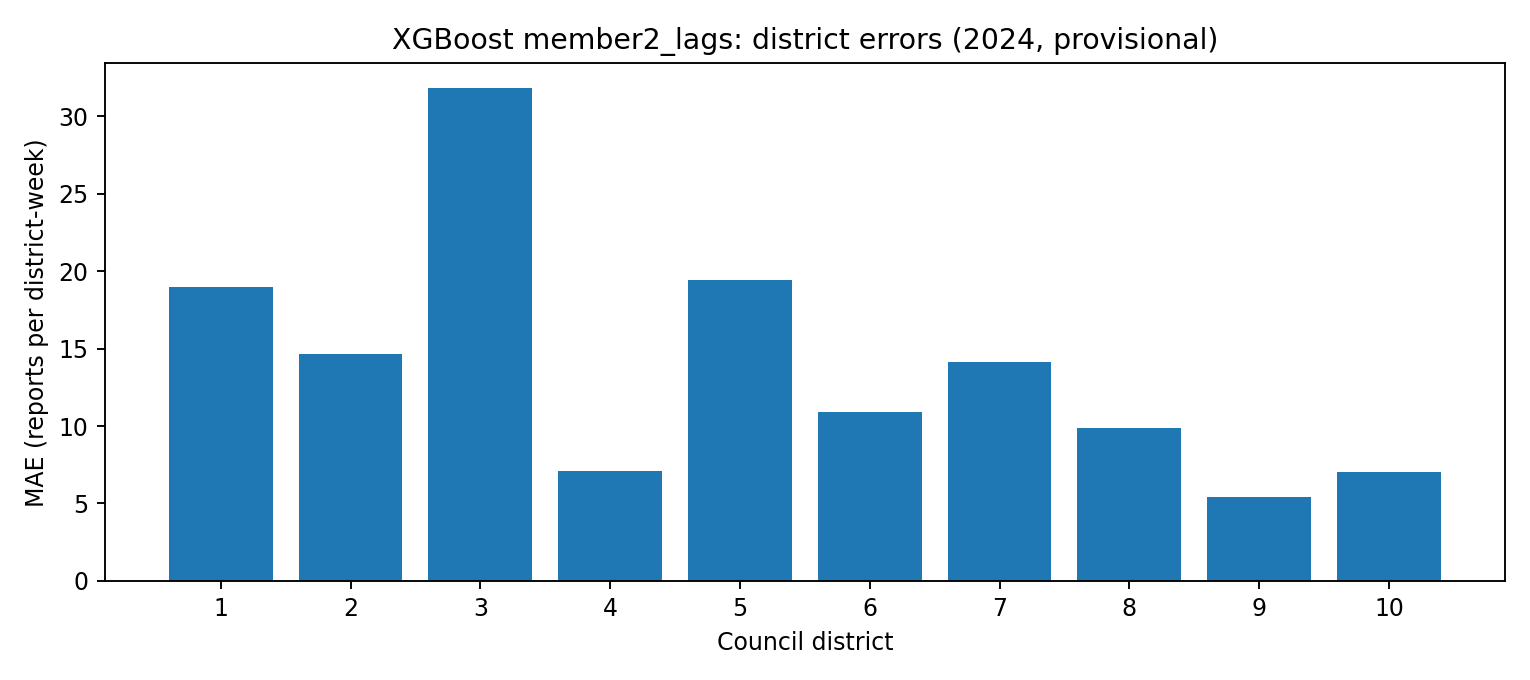

In [3]:
focus_district = m4.primary_rows(outputs['district_metrics'], primary_experiment).sort_values('mae', ascending=False)
print('District diagnostics for:', primary_experiment)
display(focus_district[['district', 'rows', 'mae', 'rmse', 'mean_bias_prediction_minus_actual']].round(2))
highest = focus_district.iloc[0]
print(f"Highest raw-count MAE: District {highest.district} ({highest.mae:.2f} reports/district-week).")
display(Image(filename=str(ROOT / 'reports/figures/member4_xgboost/district_mae.png')))

## 5. Busy-week errors

A busy district-week is defined using that district's 90th-percentile weekly count in the 2020–2023 training period. Citywide busy weeks use the corresponding training-period percentile of weekly citywide totals.

The observed 2024 count determines busy-week membership only *after* forecasting, for retrospective error analysis. It is never an input feature or a claim that future busy weeks can be identified in advance. Bias is `prediction − actual` (negative means underprediction).


District-busy diagnostic for: member2_lags


,busy_district_week,rows,mae,rmse,mean_bias_prediction_minus_actual
2,False,397,11.01,15.52,3.67
3,True,123,23.42,30.77,-22.19


Citywide-busy diagnostic for: member2_lags


,busy_citywide_week,rows,mae,rmse,mean_bias_prediction_minus_actual
2,False,390,13.19,18.69,0.64
3,True,130,16.21,24.16,-11.72


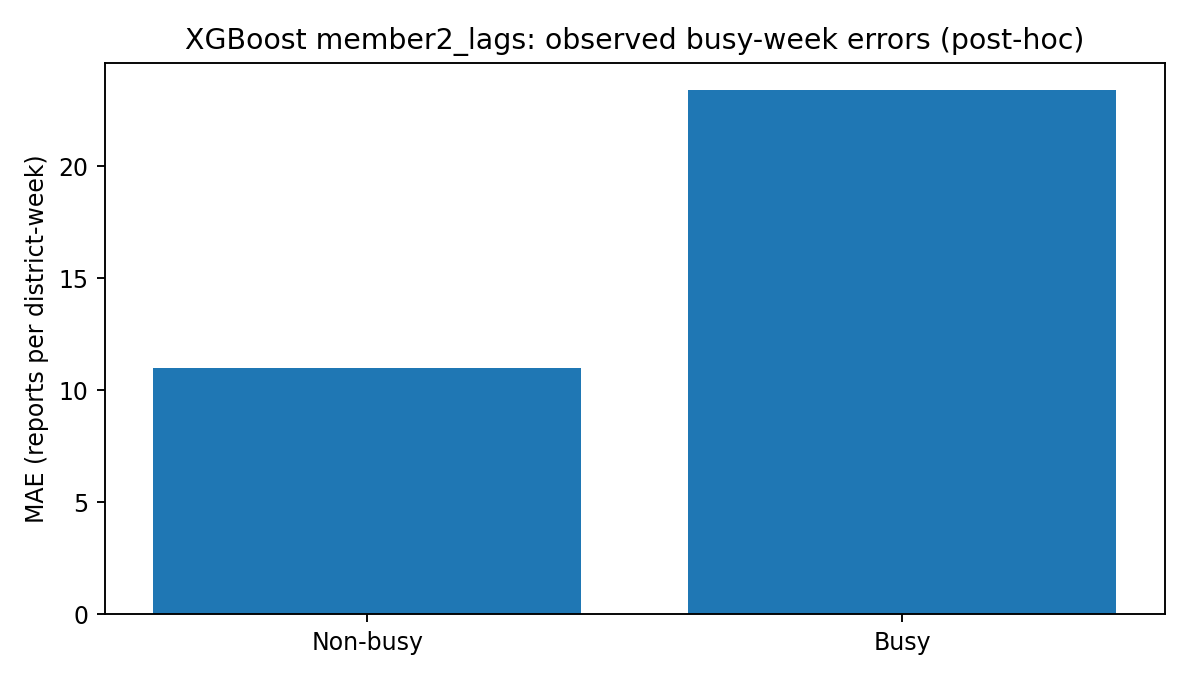

In [4]:
busy = m4.primary_rows(outputs['busy_week_metrics'], primary_experiment).sort_values('busy_district_week')
city_busy = m4.primary_rows(outputs['citywide_busy_week_metrics'], primary_experiment).sort_values('busy_citywide_week')
print('District-busy diagnostic for:', primary_experiment)
display(busy[['busy_district_week', 'rows', 'mae', 'rmse', 'mean_bias_prediction_minus_actual']].round(2))
print('Citywide-busy diagnostic for:', primary_experiment)
display(city_busy[['busy_citywide_week', 'rows', 'mae', 'rmse', 'mean_bias_prediction_minus_actual']].round(2))
display(Image(filename=str(ROOT / 'reports/figures/member4_xgboost/busy_week_mae.png')))

## 6. Citywide trend and feature importance

The weekly plot sums predictions across districts, while validation MAE/RMSE remain calculated per district-week. The importance chart uses the same primary XGBoost configuration as the error analyses.

Feature importance describes model associations, not causal effects.


Forecast and importance plots for: member2_lags


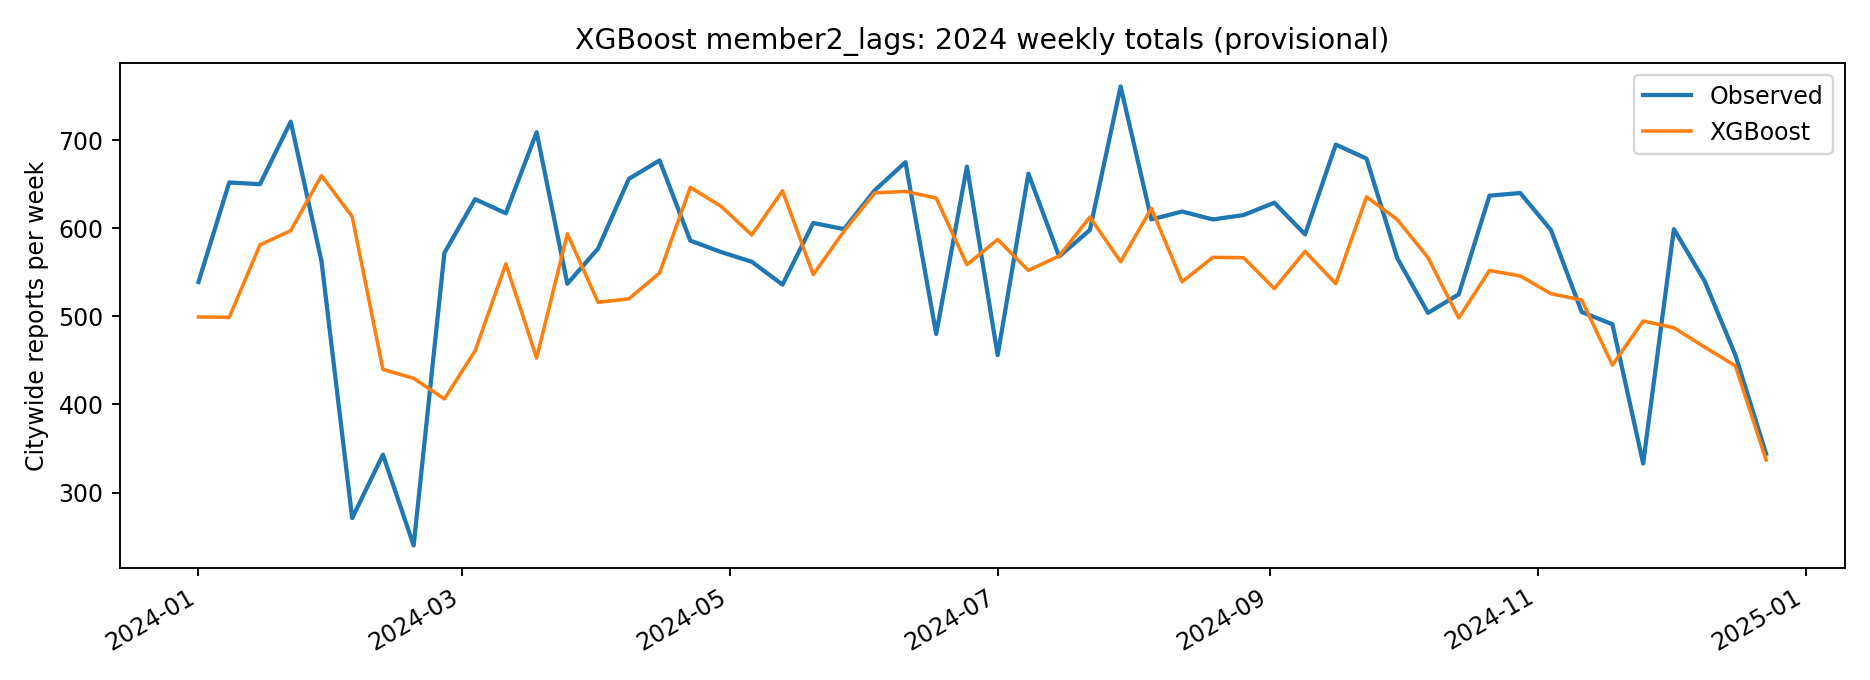

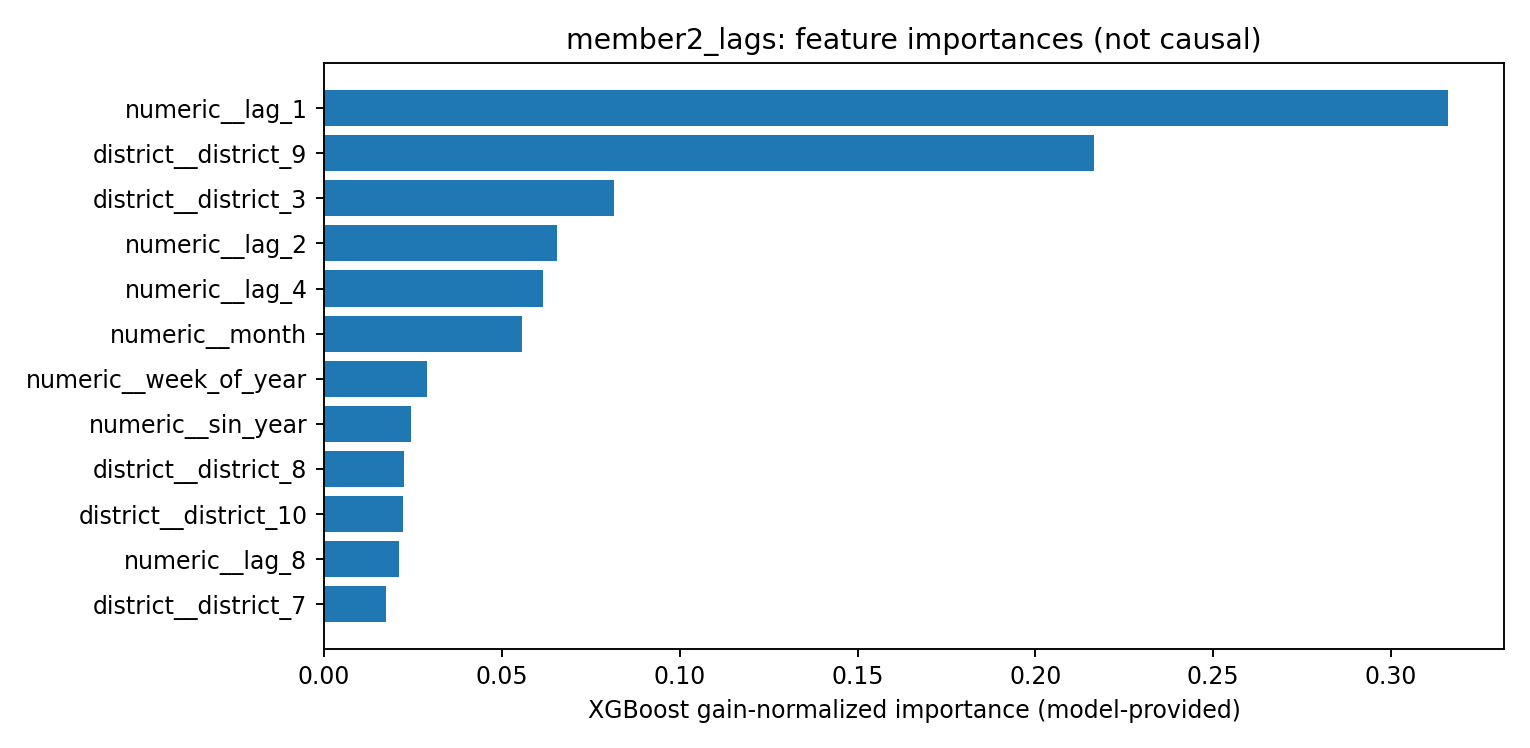

Top predictive inputs: member2_lags


,feature,importance
31,numeric__lag_1,0.3161
25,district__district_9,0.2165
19,district__district_3,0.0815
32,numeric__lag_2,0.0656
33,numeric__lag_4,0.0615
27,numeric__month,0.0557
28,numeric__week_of_year,0.0290
29,numeric__sin_year,0.0245
24,district__district_8,0.0224
26,district__district_10,0.0223


In [5]:
print('Forecast and importance plots for:', primary_experiment)
display(Image(filename=str(ROOT / 'reports/figures/member4_xgboost/weekly_citywide.png')))
display(Image(filename=str(ROOT / 'reports/figures/member4_xgboost/feature_importance.png')))
print('Top predictive inputs:', primary_experiment)
focus_importance = m4.primary_rows(outputs['feature_importance'], primary_experiment)
display(focus_importance.nlargest(10, 'importance')[['feature', 'importance']].round({'importance': 4}))

## 7. Interpretation and next steps

- Feature comparison: a smaller lag-based feature set can match or outperform a broader set on 2024 validation, but this ranking may not generalize.
- Error analysis: district-level differences and underprediction during high-demand periods may be operationally important. Busy-week groups are retrospective.
- Data quality: verify district boundaries, reporting coverage, and the treatment of missing versus zero-count weeks with the team.
- This XGBoost experiment covers 2024 validation. The frozen 2025 evaluation covers Poisson and two baselines.

In [6]:
print('DATA INTEGRITY / REPRODUCIBILITY')
for name in ['primary_analysis_experiment', 'train_window', 'validation',
             'final_test_2025_accessed', 'panel_sha256',
             'validation_week_count', 'validation_district_count', 'status']:
    print(f'{name}: {manifest[name]}')
print('Result tables: results/member4_xgboost/')
print('Figures: reports/figures/member4_xgboost/')

DATA INTEGRITY / REPRODUCIBILITY
primary_analysis_experiment: member2_lags
train_window: 2020-2023
validation: 2024
final_test_2025_accessed: False
panel_sha256: 86d08b628aff56be4a9cf7fbc7a98d06c2937cad8fcd8d5880e5541e9bd890ed
validation_week_count: 52
validation_district_count: 10
status: provisional
Result tables: results/member4_xgboost/
Figures: reports/figures/member4_xgboost/
